## Category contract

The model predicts Network, VPN, Software, Hardware, Password Reset, Email, and Security. Ambiguous rows are excluded instead of being forced into a label.

In [1]:
from pathlib import Path
import re
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED = 42
CATEGORIES = ['Network', 'VPN', 'Software', 'Hardware', 'Password Reset', 'Email', 'Security']
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'ml' else Path.cwd()
DATA_DIR = PROJECT_ROOT / 'data'
MODEL_DIR = PROJECT_ROOT / 'ml' / 'models'
KAGGLE_PATH = DATA_DIR / 'all_tickets_processed_improved_v3.csv'
HF_PATH = DATA_DIR / 'aa_dataset-tickets-multi-lang-5-2-50-version.csv'
SYNTHETIC_PATH = DATA_DIR / 'synthetic_tickets.csv'
print('Python:', sys.version)
print('Project root:', PROJECT_ROOT)

Python: 3.11.7 (tags/v3.11.7:fa7a6f2, Dec  4 2023, 19:24:49) [MSC v.1937 64 bit (AMD64)]
Project root: d:\Infosys Springboard\AI-Powered-Customer-Support-Group2


## 1. Load source datasets

In [2]:
kaggle_df = pd.read_csv(KAGGLE_PATH)
hf_df = pd.read_csv(HF_PATH, low_memory=False)
print('Kaggle shape:', kaggle_df.shape)
print('Hugging Face shape:', hf_df.shape)
display(kaggle_df.head(3))
display(hf_df.head(3))

Kaggle shape: (47837, 2)
Hugging Face shape: (28587, 16)


,Document,Topic_group
0,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,Hardware


,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
0,Wesentlicher Sicherheitsvorfall,"Sehr geehrtes Support-Team,\n\nich möchte eine...",Vielen Dank für die Meldung des kritischen Sic...,Incident,Technical Support,high,de,51,Security,Outage,Disruption,Data Breach,NaN,NaN,NaN,NaN
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to...","Thank you for reaching out, <name>. We are awa...",Incident,Technical Support,high,en,51,Account,Disruption,Outage,IT,Tech Support,NaN,NaN,NaN
2,Query About Smart Home System Integration Feat...,"Dear Customer Support Team,\n\nI hope this mes...",Thank you for your inquiry. Our products suppo...,Request,Returns and Exchanges,medium,en,51,Product,Feature,Tech Support,NaN,NaN,NaN,NaN,NaN


## 2. Clean English Hugging Face rows

The answer column is excluded because it is the support response, not the user's problem. Using it would cause leakage.

In [3]:
tag_columns = [f'tag_{i}' for i in range(1, 9)]
hf_en = hf_df[hf_df['language'].astype(str).str.lower().eq('en')].copy()
hf_en['text'] = (hf_en['subject'].fillna('').astype(str) + ' ' + hf_en['body'].fillna('').astype(str))
hf_en['text'] = hf_en['text'].str.replace(r'\s+', ' ', regex=True).str.strip()
hf_en = hf_en[hf_en['text'].ne('')].drop_duplicates(subset=['text']).copy()
hf_en['all_tags'] = hf_en[tag_columns].fillna('').astype(str).agg(' | '.join, axis=1)
print('Clean English rows:', len(hf_en))

Clean English rows: 16338


## 3. Define conservative labelling rules

Trusted tags are used only when exactly one of the four trusted tags is present. VPN, password-reset, and email use explicit wording.

In [4]:
def has_tag(frame, tag):
    return frame[tag_columns].eq(tag).any(axis=1)

def text_matches(frame, pattern):
    return frame['text'].str.contains(pattern, case=False, regex=True, na=False)

trusted_tags = ['Security', 'Network', 'Hardware', 'Software']
for tag in trusted_tags:
    hf_en[f'has_{tag.lower()}_tag'] = has_tag(hf_en, tag)
tag_flags = [f'has_{tag.lower()}_tag' for tag in trusted_tags]
hf_en['target_tag_count'] = hf_en[tag_flags].sum(axis=1)
print(hf_en['target_tag_count'].value_counts().sort_index())

target_tag_count
0    10043
1     5281
2      931
3       82
4        1
Name: count, dtype: int64


## 4. Label Hugging Face rows

In [5]:
hf_labeled = hf_en[['text', 'all_tags']].copy()
hf_labeled['category'] = pd.NA
hf_labeled['label_method'] = pd.NA

# VPN is specific enough to take priority over a general Network tag
vpn_mask = hf_en['text'].str.contains(
    r'\bvpn\b',
    case=False,
    regex=True,
    na=False
)

hf_labeled.loc[vpn_mask, 'category'] = 'VPN'
hf_labeled.loc[vpn_mask, 'label_method'] = 'explicit_keyword'

# Apply trusted tags only to rows not already labelled as VPN
for category in trusted_tags:
    mask = (
        hf_labeled['category'].isna()
        & hf_en[f'has_{category.lower()}_tag']
        & hf_en['target_tag_count'].eq(1)
    )

    hf_labeled.loc[mask, 'category'] = category
    hf_labeled.loc[mask, 'label_method'] = 'unique_tag'

# Apply password-reset and email rules to remaining rows
unlabeled = hf_labeled['category'].isna()

password_mask = (
    unlabeled
    & hf_en['text'].str.contains(
        r'\bforgot (my )?password\b|'
        r'\bpassword reset\b|'
        r'\breset (my )?password\b|'
        r'\baccount locked\b|'
        r'\bcredentials expired\b',
        case=False,
        regex=True,
        na=False
    )
)

email_mask = (
    unlabeled
    & hf_en['text'].str.contains(
        r'\boutlook\b|\bmailbox\b|'
        r'\bcannot send\b|\bcannot receive\b|'
        r'\bsend and receive\b',
        case=False,
        regex=True,
        na=False
    )
)

hf_labeled.loc[password_mask, 'category'] = 'Password Reset'
hf_labeled.loc[password_mask, 'label_method'] = 'explicit_keyword'

hf_labeled.loc[email_mask, 'category'] = 'Email'
hf_labeled.loc[email_mask, 'label_method'] = 'explicit_keyword'

hf_labeled['source'] = 'huggingface'
hf_labeled = hf_labeled.dropna(subset=['category']).copy()

display(hf_labeled['category'].value_counts())

C:\Users\ARITRAJIT GUHA\AppData\Local\Temp\ipykernel_32780\2047082501.py:32: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  & hf_en['text'].str.contains(


category
Security          3202
Network           1382
Software           338
Hardware           326
VPN                 50
Email               36
Password Reset       2
Name: count, dtype: int64

## 5. Prepare conservative Kaggle labels

Hardware is retained from the original Hardware label. Access becomes Password Reset only when the text explicitly mentions password or login trouble. Other broad labels are excluded.

In [6]:
kaggle_clean = kaggle_df.rename(columns={'Document': 'text', 'Topic_group': 'source_label'}).copy()
kaggle_clean['text'] = kaggle_clean['text'].fillna('').astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
kaggle_clean = kaggle_clean[kaggle_clean['text'].ne('')].drop_duplicates(subset=['text']).copy()
hardware_mask = kaggle_clean['source_label'].eq('Hardware')
access_password_mask = kaggle_clean['source_label'].eq('Access') & kaggle_clean['text'].str.contains(r'\bpassword\b|\blogin\b|\bcredential\b|\blocked\b', case=False, regex=True, na=False)
kaggle_labeled = pd.concat([
    pd.DataFrame({'text': kaggle_clean.loc[hardware_mask, 'text'], 'all_tags': '', 'category': 'Hardware', 'label_method': 'kaggle_hardware', 'source': 'kaggle'}),
    pd.DataFrame({'text': kaggle_clean.loc[access_password_mask, 'text'], 'all_tags': '', 'category': 'Password Reset', 'label_method': 'kaggle_access_keyword', 'source': 'kaggle'})
], ignore_index=True)
print(kaggle_labeled['category'].value_counts())

category
Hardware          13617
Password Reset     1339
Name: count, dtype: int64


## 6. Combine, audit, and deduplicate

In [7]:
processed = pd.concat([hf_labeled, kaggle_labeled], ignore_index=True)
processed['text'] = processed['text'].astype(str).str.strip()
processed = processed[processed['category'].isin(CATEGORIES)].drop_duplicates(subset=['text']).reset_index(drop=True)
processed.insert(0, 'ticket_id', np.arange(1, len(processed) + 1))
print('Processed shape:', processed.shape)
display(processed['category'].value_counts().reindex(CATEGORIES, fill_value=0))
display(processed.sample(min(10, len(processed)), random_state=SEED))

Processed shape: (20292, 6)


category
Network            1382
VPN                  50
Software            338
Hardware          13943
Password Reset     1341
Email                36
Security           3202
Name: count, dtype: int64

,ticket_id,text,all_tags,category,label_method,source
4106,4107,Unapproved Entry Incident: Medical Data Compro...,Security | Virus | IT | Tech Support | | | |,Security,unique_tag,huggingface
3752,3753,Concerning Medical Data Security There have be...,Security | Virus | IT | Tech Support | Mainten...,Security,unique_tag,huggingface
7885,7886,license for friday july re connect hi thanks l...,,Hardware,kaggle_hardware,kaggle
9202,9203,new wallpaper roll out screen resolutions tues...,,Hardware,kaggle_hardware,kaggle
6424,6425,laptop refresh etc refresh etc hi since few ye...,,Hardware,kaggle_hardware,kaggle
12870,12871,monitor change tuesday july pm monitor change ...,,Hardware,kaggle_hardware,kaggle
14974,14975,external phone dialing issue sent wednesday ex...,,Hardware,kaggle_hardware,kaggle
12933,12934,replace cable replace cable hello please open ...,,Hardware,kaggle_hardware,kaggle
11044,11045,add to friday november report today friday nov...,,Hardware,kaggle_hardware,kaggle
9438,9439,replace trio camera meeting room friday march ...,,Hardware,kaggle_hardware,kaggle


## 7. Split real data before augmentation

In [8]:
train_real, test_df = train_test_split(processed, test_size=0.20, random_state=SEED, stratify=processed['category'])
train_real = train_real.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
print('Real training rows:', len(train_real))
print('Held-out test rows:', len(test_df))
display(test_df['category'].value_counts().reindex(CATEGORIES, fill_value=0))

Real training rows: 16233
Held-out test rows: 4059


category
Network            276
VPN                 10
Software            68
Hardware          2789
Password Reset     268
Email                7
Security           641
Name: count, dtype: int64

## 8. Optional reviewed synthetic augmentation

If data/synthetic_tickets.csv exists, it must contain reviewed rows with text and category. It is added only to training data, never to test data.

In [9]:
if SYNTHETIC_PATH.exists():
    synthetic = pd.read_csv(SYNTHETIC_PATH)
    missing = {'text', 'category'} - set(synthetic.columns)
    if missing:
        raise ValueError(f'Synthetic file is missing columns: {missing}')
    synthetic = synthetic[['text', 'category']].copy()
    synthetic['text'] = synthetic['text'].fillna('').astype(str).str.strip()
    synthetic = synthetic[synthetic['text'].ne('') & synthetic['category'].isin(CATEGORIES)]
    synthetic['source'] = 'synthetic'
    synthetic['label_method'] = 'reviewed_synthetic'
    synthetic['all_tags'] = ''
    train_df = pd.concat([train_real, synthetic], ignore_index=True).drop_duplicates(subset=['text'])
    print('Synthetic rows added:', len(synthetic))
else:
    train_df = train_real.copy()
    print('No synthetic file found; using real training rows only.')
display(train_df['category'].value_counts().reindex(CATEGORIES, fill_value=0))

No synthetic file found; using real training rows only.


category
Network            1106
VPN                  40
Software            270
Hardware          11154
Password Reset     1073
Email                29
Security           2561
Name: count, dtype: int64

## 9. Feature engineering with TF-IDF

Unigrams represent individual words. Bigrams represent two-word phrases such as password reset or no internet.

In [10]:
vectorizer = TfidfVectorizer(lowercase=True, strip_accents='unicode', ngram_range=(1, 2), min_df=2, max_features=100_000, sublinear_tf=True)
X_train = vectorizer.fit_transform(train_df['text'])
X_test = vectorizer.transform(test_df['text'])
y_train = train_df['category']
y_test = test_df['category']
print('Training matrix:', X_train.shape)
print('Test matrix:', X_test.shape)

Training matrix: (16233, 88754)
Test matrix: (4059, 88754)


## 10. Train Logistic Regression

In [11]:
category_model = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED)
category_model.fit(X_train, y_train)
predictions = category_model.predict(X_test)
print('Training complete.')

Training complete.


## 11. Evaluate accuracy, macro-F1, and confusion matrix

Accuracy: 0.9650160137965016
                precision    recall  f1-score   support

       Network       0.84      0.96      0.90       276
           VPN       1.00      0.90      0.95        10
      Software       0.56      0.93      0.70        68
      Hardware       0.99      0.97      0.98      2789
Password Reset       0.93      0.94      0.94       268
         Email       1.00      0.86      0.92         7
      Security       1.00      0.95      0.97       641

      accuracy                           0.97      4059
     macro avg       0.90      0.93      0.91      4059
  weighted avg       0.97      0.97      0.97      4059



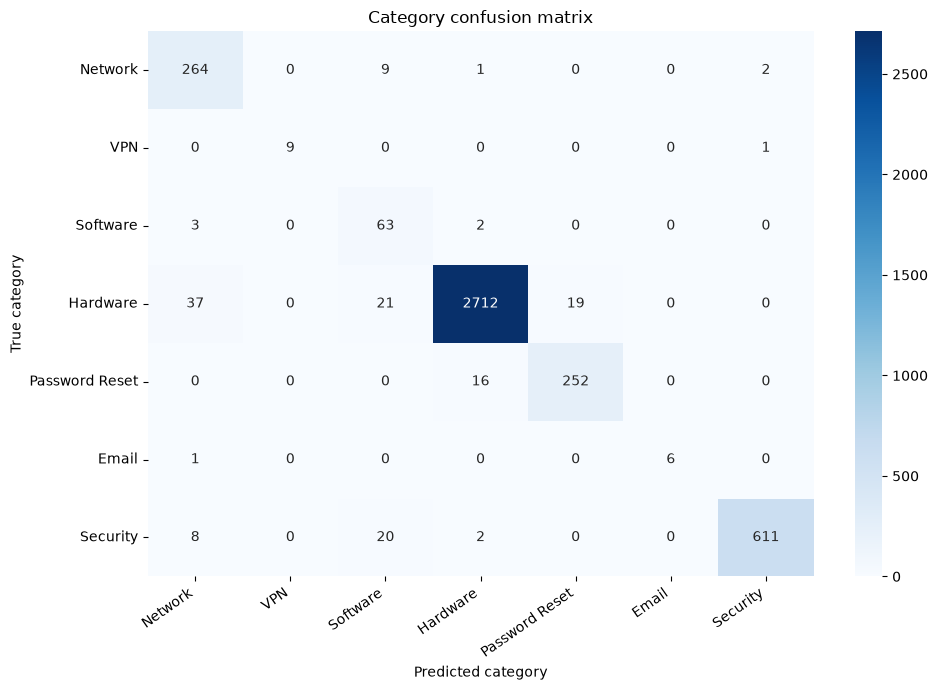

In [12]:
print('Accuracy:', accuracy_score(y_test, predictions))
print(classification_report(y_test, predictions, labels=CATEGORIES, zero_division=0))
cm = confusion_matrix(y_test, predictions, labels=CATEGORIES)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CATEGORIES, yticklabels=CATEGORIES)
plt.xlabel('Predicted category')
plt.ylabel('True category')
plt.title('Category confusion matrix')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## 12. Error analysis

In [13]:
error_df = test_df[['text', 'category']].copy()
error_df['predicted_category'] = predictions
errors = error_df[error_df['category'] != error_df['predicted_category']]
print('Errors:', len(errors))
display(errors.head(30))

Errors: 142


,text,category,predicted_category
63,check oracle account requested for hi intern h...,Hardware,Password Reset
83,"Customer Support, you've reported issues with ...",Hardware,Network
156,Report of System Malfunction Dear Customer Sup...,Hardware,Software
188,Login Difficulties Identified Users are experi...,Security,Network
261,credentials to be added october credentials ad...,Password Reset,Hardware
273,can log to sent thursday december can log hi l...,Hardware,Password Reset
332,Encountering Unanticipated System Crashes in S...,Hardware,Network
371,Issue with Recent Software Update Project mana...,Hardware,Software
446,log issue sent tuesday october log issue hi tr...,Hardware,Password Reset
545,icon question pm pm regarding lock icons files...,Password Reset,Hardware


## 13. Category-specific sub-category rules

In [14]:
SUBCATEGORY_RULES = {
    'VPN': [(r'timeout|timed out', 'Connection Timeout'), (r'authentication|credentials', 'Authentication Failure'), (r'disconnect', 'Disconnection'), (r'configuration|configure', 'Configuration')],
    'Network': [(r'wi[- ]?fi', 'Wi-Fi Disconnect'), (r'no internet|cannot connect', 'No Internet'), (r'slow', 'Slow Connection'), (r'dns', 'DNS/Connectivity'), (r'outage', 'Network Outage')],
    'Software': [(r'crash|crashes|crashing', 'Application Crash'), (r'install', 'Installation Failure'), (r'update', 'Update Error'), (r'compatib', 'Compatibility Issue'), (r'bug', 'Application Bug')],
    'Hardware': [(r'keyboard|mouse', 'Keyboard/Mouse'), (r'monitor|screen|display', 'Display'), (r'printer', 'Printer'), (r'battery|power', 'Power/Battery'), (r'audio|headset|speaker', 'Audio/Peripheral')],
    'Password Reset': [(r'forgot', 'Forgot Password'), (r'expir', 'Password Expired'), (r'lock', 'Account Locked'), (r'reset', 'Credential Reset')],
    'Email': [(r'send|receive|outbox', 'Send/Receive Failure'), (r'sync', 'Synchronisation'), (r'mailbox full|full mailbox', 'Mailbox Full'), (r'outlook', 'Outlook Access')],
    'Security': [(r'phish', 'Phishing'), (r'malware|virus', 'Malware'), (r'unauthori|suspicious login', 'Unauthorised Access'), (r'breach|leak', 'Data Breach')]
}
def predict_subcategory(text, category):
    for pattern, subcategory in SUBCATEGORY_RULES.get(category, []):
        if re.search(pattern, str(text).lower()):
            return subcategory
    return 'Other'
display(pd.DataFrame({'text': test_df['text'].head(10), 'category': predictions[:10]}).assign(subcategory=lambda frame: [predict_subcategory(t, c) for t, c in zip(frame['text'], frame['category'])]))

,text,category,subcategory
0,Problems with Accessing Medical Data Customer ...,Security,Other
1,critical alert original message sent thursday ...,Hardware,Display
2,cannot access as per error sent wednesday shee...,Hardware,Other
3,upgrade ram and cpu for a machine friday upgra...,Hardware,Other
4,Problems with Network Connectivity and Service...,Network,Wi-Fi Disconnect
5,windows updates not working sent wednesday re ...,Hardware,Display
6,flickering display monitor sent friday monitor...,Hardware,Display
7,windows updates not working on new builds upda...,Hardware,Other
8,project not aggregating at upper levels sent m...,Hardware,Other
9,Query on Security Practices for Medical Data i...,Security,Other


## 14. Export model and integration function

In [15]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
artifact = {'vectorizer': vectorizer, 'model': category_model, 'categories': CATEGORIES, 'subcategory_rules': SUBCATEGORY_RULES, 'seed': SEED}
model_path = MODEL_DIR / 'category_model.joblib'
joblib.dump(artifact, model_path)
print('Saved:', model_path)

Saved: d:\Infosys Springboard\AI-Powered-Customer-Support-Group2\ml\models\category_model.joblib


In [16]:
def classify_category(text):
    text = str(text).strip()
    if not text:
        return {'category': 'Unknown', 'sub_category': 'Other', 'category_confidence': 0.0}
    features = vectorizer.transform([text])
    probabilities = category_model.predict_proba(features)[0]
    index = int(np.argmax(probabilities))
    category = category_model.classes_[index]
    return {'category': category, 'sub_category': predict_subcategory(text, category), 'category_confidence': round(float(probabilities[index]), 4)}
print(classify_category('I forgot my password and my account is locked.'))

{'category': 'Password Reset', 'sub_category': 'Forgot Password', 'category_confidence': 0.9721}


## 15. Final checks

In [17]:
missing_categories = sorted(set(CATEGORIES) - set(train_df['category']))
print('Missing categories:', missing_categories)
assert isinstance(classify_category('VPN connection timed out'), dict)
assert set(classify_category('VPN connection timed out')) == {'category', 'sub_category', 'category_confidence'}
print('Notebook pipeline completed successfully.')

Missing categories: []
Notebook pipeline completed successfully.


## 16. Final exported training set

The reproducible scripts export the same train/test boundary used for the final model. Synthetic rows appear only in train.csv.

In [ ]:
final_train_df = pd.read_csv(DATA_DIR / 'train.csv')
final_test_df = pd.read_csv(DATA_DIR / 'test.csv')
print('Final train rows:', len(final_train_df))
print('Final test rows:', len(final_test_df))
display(final_train_df['category'].value_counts().reindex(CATEGORIES, fill_value=0))
display(final_test_df['category'].value_counts().reindex(CATEGORIES, fill_value=0))

## 17. Refit and export the final model with augmentation

In [ ]:
final_vectorizer = TfidfVectorizer(lowercase=True, strip_accents='unicode', ngram_range=(1, 2), min_df=2, max_features=100_000, sublinear_tf=True)
final_x_train = final_vectorizer.fit_transform(final_train_df['text'])
final_x_test = final_vectorizer.transform(final_test_df['text'])
final_model = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED)
final_model.fit(final_x_train, final_train_df['category'])
final_predictions = final_model.predict(final_x_test)
print('Final accuracy:', accuracy_score(final_test_df['category'], final_predictions))
print(classification_report(final_test_df['category'], final_predictions, labels=CATEGORIES, zero_division=0))
joblib.dump({'vectorizer': final_vectorizer, 'model': final_model, 'categories': CATEGORIES, 'subcategory_rules': SUBCATEGORY_RULES, 'seed': SEED}, MODEL_DIR / 'category_model.joblib')

## 18. Final integration smoke test

In [ ]:
print(classify_category('VPN connection timed out while working remotely.'))
print(classify_category('I forgot my password and the account is locked.'))
print(classify_category('Outlook cannot send messages.'))